# 05. Ranking: датасет кандидатов и опорная линия

Стадия: ranking. Retrieval — iALS со 128 факторами (E05). Ranking-модель будет получать для каждого пользователя 100 кандидатов от retrieval и переупорядочивать их по признакам.

В этом ноутбуке шаг 1: датасет «пользователь, кандидат, метка» без утечки, проверка, что утечки нет, и опорная линия ranking — порядок самого retrieval. Код: `packages/training/src/training/ranking/dataset.py`; данные: `data/processed/ranking_v0/` (собрать: `uv run python -m training.ranking.dataset`).

## Как строится датасет

Метка 1 — кандидат, который пользователь досмотрел, но мы его спрятали. Чтобы retrieval не «знал» спрятанное (утечка), train-пользователей делим на 5 частей, и для каждой части iALS обучается на остальных четырёх. Для своей части эти люди новые, как val-пользователи для итоговой модели:

- `input` — всё, кроме спрятанного: исключается из кандидатов, его `completed` дают вектор пользователя;
- `target` — 20% его `completed` (не меньше одного): это метки 1.

Для val кандидаты дают iALS, обученный на всех train-пользователях: это ровно та ситуация, в которой ranking будет работать.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training.evaluation import metrics, protocol, stats
from training.interactions import store
from training.ranking import dataset as rd

candidates = pd.read_csv(rd.OUTPUT / "candidates.csv")
targets = pd.read_csv(rd.OUTPUT / "targets.csv")
candidates.head()

D:\Projects\Python\ml\shikimori-rec-sys\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,group,fold,user_id,anime_id,retrieval_score,retrieval_rank,label
0,train,0,5850,20,1.140049,1,1
1,train,0,5850,33486,1.090778,2,1
2,train,0,5850,10793,0.985001,3,0
3,train,0,5850,51009,0.941906,4,1
4,train,0,5850,38691,0.941375,5,1


In [2]:
summary = candidates.groupby("group").agg(
    rows=("label", "size"),
    users=("user_id", "nunique"),
    positive_share=("label", "mean"),
)
summary.round(4)

,rows,users,positive_share
group,,,
train,138600,1386,0.2153
val,17300,173,0.2005


## Проверка, что утечки нет

`recall@100` по частям: какая доля спрятанных ответов попала в 100 кандидатов. Если бы iALS видел спрятанное у train-пользователей, у их частей значение было бы заметно выше, чем у val (в прошлой проверке с утечкой получалось 0,664 против честных 0,577). Здесь они должны быть близки.

In [3]:
rd.recall_of_candidates(candidates, targets).round(4)

group  fold
train   0      0.6374
        1      0.6170
        2      0.6557
        3      0.6377
        4      0.6268
val    -1      0.6465
Name: recall, dtype: float64

## Насколько полезен балл retrieval

Доля позитивов по позициям в списке кандидатов (корзины по 10 позиций). Если retrieval хороший, доля падает от первых позиций к последним. Ranking имеет смысл, если внутри этого порядка ещё есть что улучшать.

group,train,val
rank_bucket,,
1,0.536,0.518
11,0.345,0.331
21,0.257,0.243
31,0.210,0.204
41,0.184,0.168
51,0.154,0.131
61,0.138,0.118
71,0.120,0.112
81,0.108,0.094


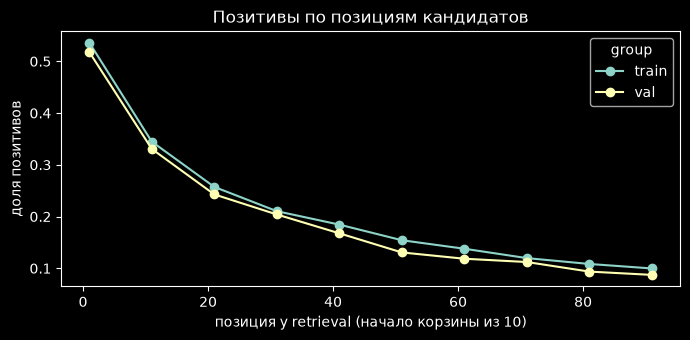

In [5]:
candidates["rank_bucket"] = (candidates["retrieval_rank"] - 1) // 10 * 10 + 1
by_rank = candidates.groupby(["group", "rank_bucket"])["label"].mean().unstack(0)

ax = by_rank.plot(marker="o", figsize=(7, 3.5))
ax.set_xlabel("позиция у retrieval (начало корзины из 10)")
ax.set_ylabel("доля позитивов")
ax.set_title("Позитивы по позициям кандидатов")
plt.tight_layout()
by_rank.round(3)

Ранжированию есть что делать. Даже на местах 51–100 попадается 9–15% правильных ответов. Если CatBoost по другим признакам (жанры, студия, популярность) поймёт, какие из них подходят, он поднимет их в топ-10.

## Опорная линия для ranking

Ranking будет переупорядочивать 100 кандидатов. Самое простое — оставить порядок retrieval. Посчитаем на val те же метрики итогового списка, что и раньше (`ndcg@10`, `hit_rate@10`, `recall@10`); спрятанные ответы считаем полностью, включая не попавшие в кандидаты, поэтому числа сравнимы с прошлыми ноутбуками. Любая ranking-модель должна обогнать эту строку.

In [6]:
table, catalog = store.load_interactions()
cases = protocol.build_cases(table, "val")


def list_metrics(scored: pd.DataFrame, score_column: str, ks=(10, 20)) -> pd.DataFrame:
    """Метрики по каждому val-пользователю для порядка кандидатов по score_column (по убыванию)."""
    rows = {}
    for user_id, group in scored.groupby("user_id"):
        ranked = group.sort_values(score_column, ascending=False)["anime_id"].to_numpy()
        targets_u = cases[user_id][1]
        row = {}
        for k in ks:
            row[f"recall@{k}"] = metrics.recall_at_k(ranked, targets_u, k)
            row[f"hit_rate@{k}"] = metrics.hit_rate_at_k(ranked, targets_u, k)
            row[f"ndcg@{k}"] = metrics.ndcg_at_k(ranked, targets_u, k)
        rows[user_id] = row
    return pd.DataFrame.from_dict(rows, orient="index")


val = candidates[candidates["group"] == "val"]
baseline = list_metrics(val, "retrieval_score")
baseline_summary = pd.DataFrame({
    m: {"среднее": baseline[m].mean(), **dict(zip(["нижняя", "верхняя"], stats.bootstrap_ci(baseline[m].to_numpy())))}
    for m in ["ndcg@10", "hit_rate@10", "recall@10"]
}).T
baseline_summary.round(4)

,среднее,нижняя,верхняя
ndcg@10,0.5976,0.5581,0.6380
hit_rate@10,0.9711,0.9422,0.9942
recall@10,0.2555,0.2233,0.2865


Вывод по шагу 1:

- Датасет: 1386 train-пользователей (по 100 кандидатов, всего 138 600 строк) и 173 val-пользователя (17 300 строк); позитивов около 21%.
- Утечки нет: `recall@100` у пяти train-частей 0,617–0,656, у val 0,647. Если бы iALS видел спрятанное, у train было бы заметно выше.
- Значение `recall@100` у val совпадает с результатом E05 (0,6465), то есть кандидаты построены той же моделью, что и в сравнении retrieval.
- Опорная линия ranking — порядок retrieval; её метрики в таблице выше. Следующий шаг — признаки для каждой пары «пользователь, кандидат» и первая ranking-модель.

## Шаг 2: CatBoost с признаками аниме

Модель — `CatBoostRanker` с функцией потерь `YetiRank`: она учит порядок внутри списка 100 кандидатов каждого пользователя с упором на верх списка. Код: `packages/training/src/training/ranking/model.py`, признаки аниме: `packages/core/src/core/catalog/anime.py` (этот модуль общий для обучения и будущей выдачи, чтобы признаки считались одинаково).

Признаки:
- от iALS: балл и место кандидата;
- популярность: `log(1 + число train-зрителей)`, для train-частей — без пользователей своей части (иначе утечка);
- аниме: год, число серий, длительность серии, общая длительность; тип, возрастной рейтинг, первоисточник, студия (категориальные, CatBoost кодирует их сам).

Текущие `score`, `status`, `episodes_aired` аниме не используем: это сегодняшнее состояние сайта, утечка из будущего.

In [7]:
from core.catalog import anime
from training.ranking import model as rk

data, columns = rk.prepare()
data[columns].head()

,retrieval_score,retrieval_rank,popularity,year,episodes,duration,total_minutes,kind,rating,origin,studio
0,1.140049,1,6.137727,2002.0,220.0,23.0,5060.0,tv,pg_13,manga,1
1,1.090778,2,5.958425,2017.0,25.0,23.0,575.0,tv,pg_13,manga,4
2,0.985001,3,5.117994,2011.0,22.0,24.0,528.0,tv,r,original,10
3,0.941906,4,6.274762,2023.0,23.0,23.0,529.0,tv,r,manga,569
4,0.941375,5,6.089045,2019.0,24.0,24.0,576.0,tv,pg_13,manga,73


### Связь признаков между собой и с меткой

Ранговая корреляция (Спирмена) числовых признаков на train-кандидатах. Строка `label` показывает, насколько признак сам по себе связан с тем, что кандидат оказался спрятанным ответом. Это связь по всем строкам сразу, без учёта, что сравнивать надо внутри списка одного пользователя, поэтому это ориентир, а не оценка полезности признака.

retrieval_rank    -0.279123
duration          -0.013577
year              -0.011187
total_minutes      0.023999
episodes           0.024137
popularity         0.048041
retrieval_score    0.495649
Name: label, dtype: float64

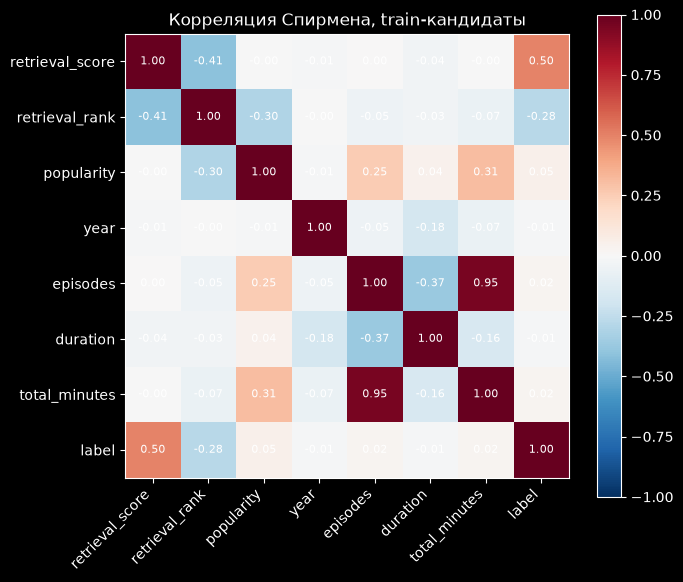

In [8]:
numeric = [c for c in columns if c not in anime.CATEGORICAL_FEATURES] + ["label"]
corr = data.loc[data["group"] == "train", numeric].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric)), numeric, rotation=45, ha="right")
ax.set_yticks(range(len(numeric)), numeric)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Корреляция Спирмена, train-кандидаты")
plt.tight_layout()
corr["label"].drop("label").sort_values()

Доля позитивов по типу аниме и первоисточнику (категориальные признаки в корреляцию не входят).

In [9]:
train_rows = data[data["group"] == "train"]
pd.concat({c: train_rows.groupby(c)["label"].agg(доля_позитивов="mean", строк="size") for c in ["kind", "origin"]}).round(3)

доля_позитивов   строк
kind   movie                     0.188   20655
       ona                       0.164    4545
       ova                       0.190    6012
       special                   0.201    3460
       tv                        0.225  101872
       tv_special                0.217    2056
origin book                      0.193     626
       card_game                 0.225      40
       four_koma_manga           0.167    1586
       game                      0.198    1094
       light_novel               0.253   33527
       manga                     0.214   68882
       mixed_media               0.172     169
       music                     0.188      32
       novel                     0.150    2947
       original                  0.175   16214
       other                     0.170     294
       picture_book              0.000       1
       visual_novel              0.225    3208
       web_manga                 0.193    9027
       web_novel                 0.187     953

### CatBoost с параметрами по умолчанию

Обучаем на всех train-кандидатах (500 итераций, темп 0,05, глубина 6), сравниваем на val с опорной линией — порядком iALS: средние, 95% интервалы и парная разница (`diff`).

In [10]:
train_pool = rk.make_pool(data[data["group"] == "train"], columns)
default_model = rk.train_ranker(train_pool)
default_report = rk.report(rk.evaluate_on_val(default_model, data, columns))
default_report.round(4)

,baseline,baseline_low,baseline_high,catboost,catboost_low,catboost_high,diff,diff_low,diff_high
ndcg@10,0.5976,0.5581,0.6380,0.6275,0.5861,0.6706,0.0299,0.0152,0.0449
hit_rate@10,0.9711,0.9422,0.9942,0.9653,0.9364,0.9884,-0.0058,-0.0173,0.0000
recall@10,0.2555,0.2233,0.2865,0.2584,0.2260,0.2897,0.0030,-0.0086,0.0140


In [11]:
pd.Series(default_model.get_feature_importance(data=train_pool), index=columns).sort_values(ascending=False).round(3)

retrieval_rank     0.038
retrieval_score    0.031
popularity         0.014
studio             0.007
year               0.004
origin             0.004
total_minutes      0.004
duration           0.002
episodes           0.002
rating             0.001
kind               0.001
dtype: float64

### Подбор параметров через Optuna

Перебираем темп обучения, глубину деревьев и регуляризацию листьев. Обучаемся на частях train 1–4 и сравниваем наборы по NDCG@10 на части 0 с ранней остановкой; **val в подборе не участвует**, иначе итоговая цифра на val была бы подогнанной. Число итераций итоговой модели — лучшая итерация из ранней остановки.

Одна попытка — около 1,5 минуты; 15 попыток — около 25 минут.

In [ ]:
N_TRIALS = 15
study = rk.tune_ranker(data, columns, n_trials=N_TRIALS, timeout=1800)
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs")).sort_values("value", ascending=False)
trials.head(10).round(4)

In [ ]:
best_params = dict(study.best_params)
best_params["iterations"] = int(study.best_trial.user_attrs["best_iteration"]) + 1
tuned_model = rk.train_ranker(train_pool, best_params)
tuned_report = rk.report(rk.evaluate_on_val(tuned_model, data, columns))
print("лучшие параметры:", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_params.items()})
tuned_report.round(4)

Вывод по шагу 2 (числа из прогона `tune_ranker` с 15 попытками и `seed = 42`; ячейки выше воспроизводят их):

- **CatBoost обгоняет порядок iALS, но немного.** С параметрами по умолчанию `ndcg@10` на val 0,628 против 0,598; парная разница +0,030 [0,015; 0,045], значима. `hit_rate@10` и `recall@10` практически не меняются: модель переставляет кандидатов внутри первой десятки, а не находит новых.
- **Признаки аниме почти не используются.** Важность: место и балл iALS 0,04 и 0,03, популярность 0,013, студия 0,006, остальные признаки аниме 0–0,003. Признаки аниме одинаковы для всех пользователей и не говорят модели, что подходит именно этому человеку.
- **Подбор параметров ничего не дал.** 15 наборов на части 0 дали NDCG@10 от 0,670 до 0,683 — разброс 0,013, то есть модель почти не чувствительна к параметрам. Лучший набор (темп 0,21, глубина 8, `l2_leaf_reg` 1,6, 89 итераций) на val даёт `ndcg@10` 0,620 (+0,022 [0,009; 0,036] к iALS) — не лучше параметров по умолчанию. Узкое место — признаки, а не настройки.
- **Следующий шаг:** признаки пары «пользователь, аниме» (совпадение жанров с историей, знакомая студия и франшиза, досмотрен ли приквел).